# 06. Deep Learning — mDeBERTa для четырёх классов риска (Kaggle GPU)

**Цель:** fine-tuning `microsoft/mdeberta-v3-base` для классификации `no_risk`, `cyber_risk`, `operational_risk`, `regulatory_risk`. Данные **те же самые**, что в бинарной задаче: 5 041 запись и исходные `train`/`valid`/`test`.

Сравниваем три конфигурации: `text_standard`, `bank_context_standard`, `bank_context_weighted`. Основная метрика выбора checkpoint и победителя — **Validation Macro F1**. По умолчанию **test отключён**.

Среда экспериментов — Kaggle с GPU и доступом к Internet для загрузки исходной модели; CSV подключён как входной набор данных.

В ноутбуке сохранены оригинальные execution_count, output и история обучения из выполненной версии Kaggle. Метрики и предсказания дополнительно представлены в CSV и JSON; веса моделей хранятся отдельно в Kaggle.


## 1. Зависимости и GPU

Используем установленную версию Transformers (поддержка 4.x/5.x). Устанавливаем только отсутствующие библиотеки; принудительно понижать `transformers`, `huggingface-hub` или `torch` не требуется.

In [1]:
import os,sys,subprocess,importlib.util
os.environ['USE_TF']='0'
os.environ['USE_FLAX']='0'
os.environ['TOKENIZERS_PARALLELISM']='false'
missing=[p for p in ('transformers','accelerate','sentencepiece','safetensors') if importlib.util.find_spec(p) is None]
if missing:
    print('Устанавливаю отсутствующие:',missing)
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
    print('После установки библиотек может потребоваться перезапуск ядра.')

## 2. Импорт и настройки

Основная серия включает три конфигурации. Проверка random seed выделена в отдельный ноутбук 08. Обучение рассчитано на GPU.

In [2]:
import gc,math,time,inspect,shutil,torch,hashlib
import torch.nn.functional as F
from transformers import (AutoTokenizer,AutoModelForSequenceClassification,Trainer,
                          TrainingArguments,DataCollatorWithPadding,EarlyStoppingCallback,set_seed)
import transformers,accelerate

from pathlib import Path
import json, hashlib, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay)
LABELS = ['no_risk','cyber_risk','operational_risk','regulatory_risk']
ID2LABEL = {i:label for i,label in enumerate(LABELS)}
LABEL2ID = {label:i for i,label in ID2LABEL.items()}
EXPECTED_SHA256 = '52333a13e7fb6f6c4162486198fbf1d1ab368672a8974295995580a1924f67f3'

def locate_dataset():
    candidates = [Path.cwd()/'data'/'bank_risk_dataset.csv',
                  Path.cwd()/'bank_risk_dataset.csv',
                  Path.cwd().parent/'data'/'bank_risk_dataset.csv',
                  Path('/kaggle/working/bank_risk_dataset.csv')]
    candidates += sorted(Path('/kaggle/input').rglob('bank_risk_dataset.csv')) if Path('/kaggle/input').exists() else []
    present = list(dict.fromkeys(p.resolve() for p in candidates if p.is_file()))
    if not present:
        raise FileNotFoundError('Не найден data/bank_risk_dataset.csv в каталоге проекта или входных данных Kaggle.')
    if len(present)>1:
        # Копии одного и того же файла допустимы, но использовать изменённые данные нельзя.
        valid=[p for p in present if hashlib.sha256(p.read_bytes()).hexdigest()==EXPECTED_SHA256]
        if not valid: raise ValueError(f'Не найден исходный неизменённый CSV среди: {present}')
        return valid[0]
    return present[0]

def load_data():
    path=locate_dataset()
    sha=hashlib.sha256(path.read_bytes()).hexdigest()
    assert sha==EXPECTED_SHA256, 'SHA256 отличается от исходного датасета. Не меняйте данные.'
    df=pd.read_csv(path)
    required={'sample_id','event_group_id','split','title','entity_norm','text_fragment','risk_type_4cls','alert_flag'}
    assert required.issubset(df.columns), f'Не хватает колонок: {required-set(df.columns)}'
    assert len(df)==5041 and df['sample_id'].is_unique
    assert set(df['split'])=={'train','valid','test'}
    assert set(df['risk_type_4cls'])==set(LABELS)
    assert (df['alert_flag'].astype(int) == df['risk_type_4cls'].ne('no_risk').astype(int)).all()
    for col in ('title','entity_norm','text_fragment'):
        df[col]=df[col].fillna('').astype(str)
    assert df['text_fragment'].str.strip().ne('').all()
    parts={s:df[df['split']==s].copy().reset_index(drop=True) for s in ('train','valid','test')}
    assert [len(parts[s]) for s in ('train','valid','test')]==[3535,755,751]
    for a,b in [('train','valid'),('train','test'),('valid','test')]:
        assert not (set(parts[a]['event_group_id']) & set(parts[b]['event_group_id'])), f'Пересечение групп: {a}/{b}'
    print('Датасет:',path,'| SHA256:',sha)
    display(pd.crosstab(df['split'],df['risk_type_4cls']).reindex(index=['train','valid','test'], columns=LABELS))
    return parts,sha

def with_title(title,text):
    title,text=title.strip(),text.strip()
    if not title or title.lower() in text[:max(300,len(title)+40)].lower():
        return text
    return title+'. '+text

def bank_context(bank,text,title):
    # Тот же алгоритм контекстного представления, что в бинарных экспериментах.
    sentences=re.split(r'(?<=[.!?])\s+',text.strip())
    words=[w for w in re.findall(r'\w+',bank.casefold()) if len(w)>=4]
    hit=[i for i,s in enumerate(sentences) if bank.casefold() in s.casefold() or any(w in s.casefold() for w in words)]
    if not hit: return with_title(title,text)
    selected=set()
    for i in hit: selected.update(range(max(0,i-1), min(len(sentences),i+2)))
    excerpt=' '.join(sentences[i] for i in sorted(selected))
    return with_title(title,excerpt)

def text_input(frame,mode):
    if mode=='text': return frame['text_fragment'].tolist()
    if mode=='bank_context':
        snippets=[bank_context(b,t,h) for b,t,h in zip(frame['entity_norm'],frame['text_fragment'],frame['title'])]
        # Для классических моделей добавляем банк текстовой меткой; DL подаёт отдельно парой.
        return ['Банк: '+b+'. '+s for b,s in zip(frame['entity_norm'],snippets)]
    raise ValueError(mode)

def evaluate(y_true,y_pred):
    y_true=np.asarray(y_true,dtype=int);y_pred=np.asarray(y_pred,dtype=int)
    f1s=f1_score(y_true,y_pred,labels=list(range(4)),average=None,zero_division=0)
    cm=confusion_matrix(y_true,y_pred,labels=list(range(4)))
    d={'macro_f1':float(f1s.mean()),'risk_macro_f1':float(f1s[1:].mean()),
       'weighted_f1':float(f1_score(y_true,y_pred,average='weighted',zero_division=0)),
       'accuracy':float(accuracy_score(y_true,y_pred)),
       'macro_precision':float(precision_score(y_true,y_pred,labels=list(range(4)),average='macro',zero_division=0)),
       'macro_recall':float(recall_score(y_true,y_pred,labels=list(range(4)),average='macro',zero_division=0)),
       'risk_recall':float(recall_score(y_true,y_pred,labels=[1,2,3],average='macro',zero_division=0))}
    for i,label in enumerate(LABELS): d['f1_'+label]=float(f1s[i])
    d['confusion_matrix']=cm.tolist()
    return d

def save_json(path,obj):
    Path(path).parent.mkdir(parents=True,exist_ok=True)
    Path(path).write_text(json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')

assert torch.cuda.is_available(),'Для выполнения требуется доступный GPU.'
print('GPU:',torch.cuda.get_device_name(0),'| torch:',torch.__version__,'| transformers:',transformers.__version__)
MODEL_ID='microsoft/mdeberta-v3-base'
MODEL_REVISION='a0484667b22365f84929a935b5e50a51f71f159d'
OUT=Path('/kaggle/working/bank_risk_multiclass_dl') if Path('/kaggle/working').exists() else Path.cwd()/'results'/'multiclass'/'dl'
OUT.mkdir(parents=True,exist_ok=True)
BATCH_SIZE=4
GRAD_ACCUM=4
MAX_TOTAL_MINUTES=170
MAX_RUNS=3
CONFIGS=[
    dict(name='text_standard',mode='text',loss_mode='standard',seed=42,max_length=256,epochs=6,learning_rate=2e-5),
    dict(name='bank_context_standard',mode='bank_context',loss_mode='standard',seed=42,max_length=256,epochs=6,learning_rate=2e-5),
    dict(name='bank_context_weighted',mode='bank_context',loss_mode='weighted',seed=42,max_length=256,epochs=6,learning_rate=2e-5),
]
assert len(CONFIGS)<=MAX_RUNS
set_seed(42)

GPU: Tesla T4 | torch: 2.11.0+cu128 | transformers: 5.16.1


## 3. Загрузка и валидация меток

Классы кодируются единым словарём `LABEL2ID`; нулевой класс означает отсутствие риска. Исключаем `found_risk_keywords`, `alert_flag` и сам `risk_type_4cls` из текстовых признаков, кроме меток обучения.

In [3]:
parts,DATA_SHA=load_data()
assert (parts['valid']['risk_type_4cls'].value_counts().reindex(LABELS,fill_value=0).to_numpy()==[715,20,13,7]).all()

Датасет: /kaggle/input/datasets/victordoynikov/bank-risks/bank_risk_dataset.csv | SHA256: 52333a13e7fb6f6c4162486198fbf1d1ab368672a8974295995580a1924f67f3


risk_type_4cls,no_risk,cyber_risk,operational_risk,regulatory_risk
split,,,,
train,3359,74,67,35
valid,715,20,13,7
test,713,17,17,4


## 4. Токенизация

Для `bank_context` используем **точно ту же функцию выделения контекста банка**, что и в бинарном исследовании. Банк и фрагмент передаются токенизатору парой текстов. Модель не получает метки и признаки с утечкой.

In [4]:
tokenizer=AutoTokenizer.from_pretrained(MODEL_ID,revision=MODEL_REVISION,use_fast=False)
collator=DataCollatorWithPadding(tokenizer=tokenizer,pad_to_multiple_of=8)
class NewsDataset(torch.utils.data.Dataset):
    def __init__(self,frame,mode='text',max_length=256):
        texts=frame['text_fragment'].tolist(); banks=frame['entity_norm'].tolist();titles=frame['title'].tolist()
        if mode=='text':
            self.encodings=tokenizer(texts,truncation=True,max_length=max_length)
        elif mode=='bank_context':
            snippets=[bank_context(b,t,h) for b,t,h in zip(banks,texts,titles)]
            self.encodings=tokenizer(banks,text_pair=snippets,truncation='only_second',max_length=max_length)
        else:raise ValueError(mode)
        self.labels=frame['risk_type_4cls'].map(LABEL2ID).astype(int).tolist()
    def __len__(self): return len(self.labels)
    def __getitem__(self,i):
        return {**{k:v[i] for k,v in self.encodings.items()},'labels':self.labels[i]}
_cache={}
def dataset(split,mode,max_length):
    key=(split,mode,max_length)
    if key not in _cache: _cache[key]=NewsDataset(parts[split],mode,max_length)
    return _cache[key]
assert len(dataset('train','text',256))==3535
print('Tokenizer и входные данные подготовлены.')

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

spm.model: downloading bytes:           |  0.00B            

Tokenizer и входные данные подготовлены.


## 5. Метрики, дисбаланс классов и аргументы обучения

**Выбор checkpoint = максимальный Macro F1 на validation.** Дополнительно сохраняются F1 каждого класса и средний F1 только трёх категорий риска.

Для Weighted Cross Entropy веса пропорциональны обратному квадратному корню частоты класса, нормированы так, чтобы средний вес по обучающим примерам был равен 1. Используем только частоты `train`. Custom loss нормируется на размер аккумулированного batch.

In [5]:
args_fields=set(inspect.signature(TrainingArguments).parameters)
trainer_fields=set(inspect.signature(Trainer).parameters)
train_counts=parts['train']['risk_type_4cls'].value_counts().reindex(LABELS).to_numpy(dtype=np.float64)
weights=(1/np.sqrt(train_counts))
weights=weights/np.average(weights,weights=train_counts)
CLASS_WEIGHTS=torch.tensor(weights,dtype=torch.float32)
print('Числа классов:',dict(zip(LABELS,train_counts.astype(int))))
print('Веса классов:',dict(zip(LABELS,weights.round(3))))

def eval_metrics(pred):
    logits=pred.predictions[0] if isinstance(pred.predictions,tuple) else pred.predictions
    pred_ids=np.asarray(logits).argmax(axis=-1)
    m=evaluate(pred.label_ids,pred_ids)
    return {k:v for k,v in m.items() if k!='confusion_matrix'}

# Обе ветки поддерживают нормализацию градиентов при gradient accumulation.
def make_loss_func(weight_tensor):
    def loss_fn(outputs,labels,num_items_in_batch=None):
        logits=outputs.logits.float()
        w=weight_tensor.to(device=logits.device,dtype=torch.float32)
        loss_sum=F.cross_entropy(logits,labels.long(),weight=w,reduction='sum')
        denom=num_items_in_batch if num_items_in_batch is not None else labels.numel()
        if torch.is_tensor(denom):denom=denom.to(logits.device).clamp_min(1)
        else:denom=max(1,int(denom))
        return loss_sum/denom
    return loss_fn

class WeightedTrainer(Trainer):
    def __init__(self,*args,weight_tensor=None,**kwargs):
        super().__init__(*args,**kwargs)
        self.weight_tensor=weight_tensor
        self.model_accepts_loss_kwargs=True
    def compute_loss(self,model,inputs,return_outputs=False,num_items_in_batch=None,**kwargs):
        labels=inputs['labels']
        outputs=model(**{k:v for k,v in inputs.items() if k!='labels'})
        loss=make_loss_func(self.weight_tensor)(outputs,labels,num_items_in_batch)
        return (loss,outputs) if return_outputs else loss

def training_args(run,cfg):
    kwargs=dict(output_dir=str(run/'checkpoints'),num_train_epochs=cfg['epochs'],
        learning_rate=cfg['learning_rate'],per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=4,gradient_accumulation_steps=GRAD_ACCUM,
        weight_decay=0.01,lr_scheduler_type='linear',optim='adamw_torch',
        max_grad_norm=1.0,fp16=not torch.cuda.is_bf16_supported(),bf16=torch.cuda.is_bf16_supported(),
        save_strategy='epoch',logging_strategy='epoch',load_best_model_at_end=True,
        metric_for_best_model='macro_f1',greater_is_better=True,save_total_limit=1,
        seed=cfg['seed'],data_seed=cfg['seed'],report_to='none',dataloader_num_workers=0)
    if 'eval_strategy' in args_fields:kwargs['eval_strategy']='epoch'
    elif 'evaluation_strategy' in args_fields:kwargs['evaluation_strategy']='epoch'
    else:raise RuntimeError('Не найдена стратегия валидации TrainingArguments')
    if 'warmup_ratio' in args_fields:kwargs['warmup_ratio']=0.1
    elif 'warmup_steps' in args_fields:
        updates=math.ceil(len(parts['train'])/(BATCH_SIZE*GRAD_ACCUM))*cfg['epochs']
        kwargs['warmup_steps']=int(math.ceil(0.1*updates))
    if 'save_only_model' in args_fields:kwargs['save_only_model']=True
    if 'save_safetensors' in args_fields:kwargs['save_safetensors']=True
    return TrainingArguments(**{k:v for k,v in kwargs.items() if k in args_fields})

def make_trainer(model,args,cfg,train_ds,valid_ds):
    kw=dict(model=model,args=args,train_dataset=train_ds,eval_dataset=valid_ds,
            data_collator=collator,compute_metrics=eval_metrics,
            callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
    if 'processing_class' in trainer_fields:kw['processing_class']=tokenizer
    elif 'tokenizer' in trainer_fields:kw['tokenizer']=tokenizer
    if cfg['loss_mode']=='standard':return Trainer(**kw)
    if 'compute_loss_func' in trainer_fields:
        return Trainer(**kw,compute_loss_func=make_loss_func(CLASS_WEIGHTS))
    return WeightedTrainer(**kw,weight_tensor=CLASS_WEIGHTS)
print('Подготовлены метрики и параметры Trainer.')

Числа классов: {'no_risk': np.int64(3359), 'cyber_risk': np.int64(74), 'operational_risk': np.int64(67), 'regulatory_risk': np.int64(35)}
Веса классов: {'no_risk': np.float64(0.756), 'cyber_risk': np.float64(5.095), 'operational_risk': np.float64(5.354), 'regulatory_risk': np.float64(7.408)}
Подготовлены метрики и параметры Trainer.


## 6. Обучение и сохранение моделей

После каждого запуска сохраняются модель `best_model/model.safetensors`, токенизатор, `metrics.json`, история эпох и `valid_predictions.csv`. После успешного сохранения удаляются промежуточные checkpoint, чтобы уменьшить размер Output. Повторный запуск в той же сессии пропустит полностью сохранённые модели.

**Важно:** веса из предыдущего бинарного исследования не являются готовым четырёхклассовым классификатором; нужен новый классификационный слой и обучение по `risk_type_4cls`.

In [6]:
start_time=time.monotonic();completed=[];run_counter=0
for cfg in CONFIGS:
    name=cfg['name'];run=OUT/'runs'/name
    run.mkdir(parents=True,exist_ok=True)
    signature={'config':cfg,'dataset_sha256':DATA_SHA,'model_id':MODEL_ID,
               'model_revision':MODEL_REVISION,'transformers_version':transformers.__version__}
    sig_path=run/'run_config.json';met_path=run/'metrics.json'
    if sig_path.exists():
        prior=json.loads(sig_path.read_text(encoding='utf-8'))
        assert prior==signature,f'Старая конфигурация отличается у {name}; не перезаписывайте без нового имени.'
    else:save_json(sig_path,signature)
    if met_path.exists() and (run/'best_model'/'model.safetensors').exists():
        print('Готово, пропуск:',name)
        completed.append(json.loads(met_path.read_text(encoding='utf-8')))
        continue
    if run_counter>=MAX_RUNS or (time.monotonic()-start_time)/60>MAX_TOTAL_MINUTES:
        print('Бюджет времени/запусков достигнут, остановка перед',name)
        break
    run_counter+=1
    set_seed(cfg['seed'])
    model=AutoModelForSequenceClassification.from_pretrained(
        MODEL_ID,revision=MODEL_REVISION,num_labels=4,id2label=ID2LABEL,label2id=LABEL2ID).float()
    assert all(p.dtype==torch.float32 for p in model.parameters() if p.requires_grad)
    ds_train=dataset('train',cfg['mode'],cfg['max_length'])
    ds_valid=dataset('valid',cfg['mode'],cfg['max_length'])
    trainer=make_trainer(model,training_args(run,cfg),cfg,ds_train,ds_valid)
    print('Обучение:',name)
    trainer.train()
    trainer.save_model(str(run/'best_model'))
    tokenizer.save_pretrained(str(run/'best_model'))
    valid_out=trainer.predict(ds_valid)
    logits=valid_out.predictions[0] if isinstance(valid_out.predictions,tuple) else valid_out.predictions
    pred_ids=np.asarray(logits).argmax(axis=-1)
    m=evaluate(valid_out.label_ids,pred_ids)
    record={'name':name,**cfg,'dataset_sha256':DATA_SHA,**{k:v for k,v in m.items() if k!='confusion_matrix'}}
    save_json(met_path,{**record,'confusion_matrix':m['confusion_matrix']})
    pd.DataFrame(trainer.state.log_history).to_csv(run/'history.csv',index=False)
    val_frame=parts['valid'][['sample_id','risk_type_4cls']].copy()
    val_frame['prediction']=[ID2LABEL[int(x)] for x in pred_ids]
    for i,label in enumerate(LABELS):val_frame['logit_'+label]=np.asarray(logits)[:,i]
    val_frame.to_csv(run/'valid_predictions.csv',index=False)
    if (run/'checkpoints').exists():shutil.rmtree(run/'checkpoints')
    completed.append(record)
    print('Validation Macro F1:',round(m['macro_f1'],4),'| Risk-only Macro F1:',round(m['risk_macro_f1'],4))
    del trainer,model,valid_out,ds_train,ds_valid
    gc.collect();torch.cuda.empty_cache()
if not completed:raise RuntimeError('Не завершён ни один эксперимент')
summary=pd.DataFrame(completed).sort_values(['macro_f1','risk_macro_f1'],ascending=False).reset_index(drop=True)
summary.to_csv(OUT/'validation_comparison.csv',index=False)
selected=summary.iloc[0]
selection={'task':'risk_type_4cls','criterion':'maximum_validation_macro_f1',
           'dataset_sha256':DATA_SHA,'name':selected['name'],
           'validation':{'macro_f1':float(selected['macro_f1']),
                         'risk_macro_f1':float(selected['risk_macro_f1'])}}
save_json(OUT/'selection.json',selection)
display(summary[['name','macro_f1','risk_macro_f1','weighted_f1','macro_precision','macro_recall']].round(4))
print('Выбрана модель:',selection['name'])

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.33GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/mdeberta-v3-base
Key                                        | Status     | 
-------------------------------------------+------------+-
mask_predictions.LayerNorm.weight          | UNEXPECTED | 
mask_predictions.classifier.bias           | UNEXPECTED | 
deberta.embeddings.word_embeddings._weight | UNEXPECTED | 
mask_predictions.dense.bias                | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight    | UNEXPECTED | 
mask_predictions.LayerNorm.bias            | UNEXPECTED | 
lm_predictions.lm_head.dense.bias          | UNEXPECTED | 
lm_predictions.lm_head.bias                | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias      | UNEXPECTED | 
mask_predictions.dense.weight              | UNEXPECTED | 
mask_predictions.classifier.weight         | UNEXPECTED | 
lm_predictions.lm_head.dense.weight        | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight 

... (46 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Validation Macro F1: 0.7381 | Risk-only Macro F1: 0.6565


,name,macro_f1,risk_macro_f1,weighted_f1,macro_precision,macro_recall
0,text_standard,0.7500,0.6718,0.9698,0.8080,0.7146
1,bank_context_standard,0.7434,0.6631,0.9703,0.8529,0.7467
2,bank_context_weighted,0.7381,0.6565,0.9689,0.7156,0.7692


Выбрана модель: text_standard


## 7. Анализ validation

Матрица ошибок и per-class classification report показывают, сколько модель распознала редких рисков, а не только большинство `no_risk`. Если какой-то риск не распознан ни разу, его F1 равен нулю, без маскировки в общей Accuracy.

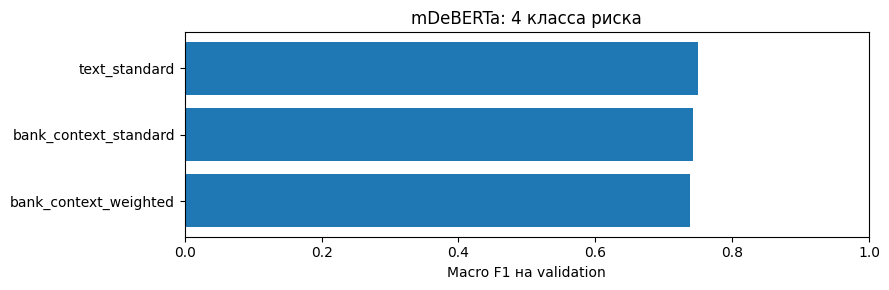

                  precision    recall  f1-score   support

         no_risk       0.98      0.99      0.98       715
      cyber_risk       0.75      0.75      0.75        20
operational_risk       0.75      0.69      0.72        13
 regulatory_risk       0.75      0.43      0.55         7

        accuracy                           0.97       755
       macro avg       0.81      0.71      0.75       755
    weighted avg       0.97      0.97      0.97       755



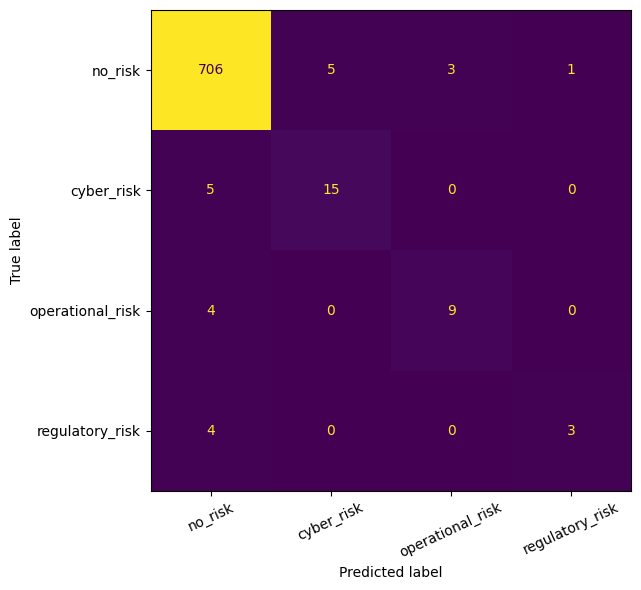

In [7]:
fig,ax=plt.subplots(figsize=(9,max(3,0.65*len(summary)+1)))
ordered=summary.sort_values('macro_f1')
ax.barh(ordered['name'],ordered['macro_f1']);ax.set_xlim(0,1);ax.set_xlabel('Macro F1 на validation');ax.set_title('mDeBERTa: 4 класса риска')
fig.tight_layout();fig.savefig(OUT/'dl_validation_macro_f1.png',dpi=150);plt.show()
winner=selection['name']
chosen=pd.read_csv(OUT/'runs'/winner/'valid_predictions.csv')
print(classification_report(chosen['risk_type_4cls'],chosen['prediction'],labels=LABELS,zero_division=0))
cm=confusion_matrix(chosen['risk_type_4cls'],chosen['prediction'],labels=LABELS)
fig,ax=plt.subplots(figsize=(8,6));ConfusionMatrixDisplay(cm,display_labels=LABELS).plot(ax=ax,values_format='d',xticks_rotation=25,colorbar=False)
fig.tight_layout();fig.savefig(OUT/'dl_validation_cm.png',dpi=150);plt.show()

## 8. Финальный test

Тестовая оценка отделена флагом `RUN_FINAL_TEST` и выполняется для зафиксированной конфигурации. Предсказание определяется через argmax четырёх логитов; пороги по test не подбираются. Итоговые результаты seed 42 сохранены отдельно и рассмотрены в ноутбуке 11.

In [8]:
RUN_FINAL_TEST=False
if RUN_FINAL_TEST:
    test_path=OUT/'test_metrics.json'
    if test_path.exists():
        print('Test уже сохранён:',json.loads(test_path.read_text(encoding='utf-8')))
    else:
        frozen=json.loads((OUT/'selection.json').read_text(encoding='utf-8'))
        cfg=json.loads((OUT/'runs'/frozen['name']/'run_config.json').read_text(encoding='utf-8'))['config']
        model=AutoModelForSequenceClassification.from_pretrained(OUT/'runs'/frozen['name']/'best_model').float()
        a=training_args(OUT/'final_eval',dict(cfg,epochs=1))
        common={'model':model,'args':a,'data_collator':collator}
        if 'processing_class' in trainer_fields:common['processing_class']=tokenizer
        elif 'tokenizer' in trainer_fields:common['tokenizer']=tokenizer
        evaluator=Trainer(**common)
        pred=evaluator.predict(dataset('test',cfg['mode'],cfg['max_length']))
        logits=pred.predictions[0] if isinstance(pred.predictions,tuple) else pred.predictions
        pred_ids=np.asarray(logits).argmax(axis=-1)
        m=evaluate(pred.label_ids,pred_ids)
        save_json(test_path,{'name':frozen['name'],'dataset_sha256':DATA_SHA,**m})
        out=parts['test'][['sample_id','risk_type_4cls']].copy()
        out['prediction']=[ID2LABEL[int(i)] for i in pred_ids]
        out.to_csv(OUT/'test_predictions.csv',index=False)
        print('FINAL TEST Macro F1:',m['macro_f1'])
        del model,evaluator,pred
        gc.collect();torch.cuda.empty_cache()
else:print('Test не запускался. Обучение и отбор моделей — только train/validation.')

Test не запускался. Обучение и отбор моделей — только train/validation.


## 9. Сохранённые результаты

В Kaggle сохранялись веса `bank_risk_multiclass_dl/runs/.../best_model/model.safetensors`, токенизатор, история эпох и предсказания. Локальные CSV и JSON основной серии находятся в `results/multiclass/dl/`; веса в локальный проект не включены.

Лучший основной вариант `text_standard`, seed 42, получил validation Macro F1 = 0,7500. Финальный test Macro F1 = 0,7329 оказался ниже результата Logistic Regression (0,8206). Для многоклассовой задачи по итоговой оценке предпочтительна Logistic Regression.